In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for f in filenames:
        print(os.path.join(dirname, f)) 

/kaggle/input/competitions/playground-series-s4e4/sample_submission.csv
/kaggle/input/competitions/playground-series-s4e4/train.csv
/kaggle/input/competitions/playground-series-s4e4/test.csv


In [3]:
import pandas as pd
import numpy as np

path = '/kaggle/input/competitions/playground-series-s4e4/'
train = pd.read_csv(path + 'train.csv')
test = pd.read_csv(path + 'test.csv')

print(train.shape, test.shape)
print(train.head())
print(train.describe())
print(train.isnull().sum())
print(train['Sex'].value_counts())

(90615, 10) (60411, 9)
   id Sex  Length  Diameter  Height  Whole weight  Whole weight.1  \
0   0   F   0.550     0.430   0.150        0.7715          0.3285   
1   1   F   0.630     0.490   0.145        1.1300          0.4580   
2   2   I   0.160     0.110   0.025        0.0210          0.0055   
3   3   M   0.595     0.475   0.150        0.9145          0.3755   
4   4   I   0.555     0.425   0.130        0.7820          0.3695   

   Whole weight.2  Shell weight  Rings  
0          0.1465        0.2400     11  
1          0.2765        0.3200     11  
2          0.0030        0.0050      6  
3          0.2055        0.2500     10  
4          0.1600        0.1975      9  
                 id        Length      Diameter        Height  Whole weight  \
count  90615.000000  90615.000000  90615.000000  90615.000000  90615.000000   
mean   45307.000000      0.517098      0.401679      0.135464      0.789035   
std    26158.441658      0.118217      0.098026      0.038008      0.457671   


In [4]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_log_error

features = ['Length', 'Diameter', 'Height', 'Whole weight',
            'Whole weight.1', 'Whole weight.2', 'Shell weight']
X = pd.get_dummies(train[['Sex'] + features], columns=['Sex'], drop_first=True).astype(float)
y = train['Rings']

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

ols = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(ols.summary())

pred = ols.predict(sm.add_constant(X_val)).clip(lower=1)
print('Validation RMSLE:', np.sqrt(mean_squared_log_error(y_val, pred)))

                            OLS Regression Results                            
Dep. Variable:                  Rings   R-squared:                       0.607
Model:                            OLS   Adj. R-squared:                  0.607
Method:                 Least Squares   F-statistic:                 1.242e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:10:40   Log-Likelihood:            -1.5266e+05
No. Observations:               72492   AIC:                         3.053e+05
Df Residuals:                   72482   BIC:                         3.054e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.8768      0.068     57.

In [5]:
ols_full = sm.OLS(y, sm.add_constant(X)).fit()

X_test = pd.get_dummies(test[['Sex'] + features], columns=['Sex'], drop_first=True).astype(float)
X_test = X_test[X.columns]
test_pred = ols_full.predict(sm.add_constant(X_test)).clip(lower=1)

sub1 = pd.DataFrame({'id': test['id'], 'Rings': test_pred})
sub1.to_csv('/kaggle/working/submission_ols.csv', index=False)
print(sub1.shape)
print(sub1.head())

(60411, 2)
      id      Rings
0  90615   8.535442
1  90616  10.029784
2  90617  10.305835
3  90618  10.956449
4  90619   7.782893


In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor

y_log = np.log1p(y)
Xtr2, Xval2, ytr2, yval2 = train_test_split(X, y_log, test_size=0.2, random_state=42)

gbm = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42)
gbm.fit(Xtr2, ytr2)
val_pred = gbm.predict(Xval2)
print('Model 2 validation RMSLE:', np.sqrt(np.mean((val_pred - yval2) ** 2)))

gbm_full = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42)
gbm_full.fit(X, y_log)
test_pred2 = np.expm1(gbm_full.predict(X_test)).clip(min=1)

sub2 = pd.DataFrame({'id': test['id'], 'Rings': test_pred2})
sub2.to_csv('/kaggle/working/submission_gbm.csv', index=False)
print(sub2.shape) 

Model 2 validation RMSLE: 0.15191500623105347
(60411, 2)


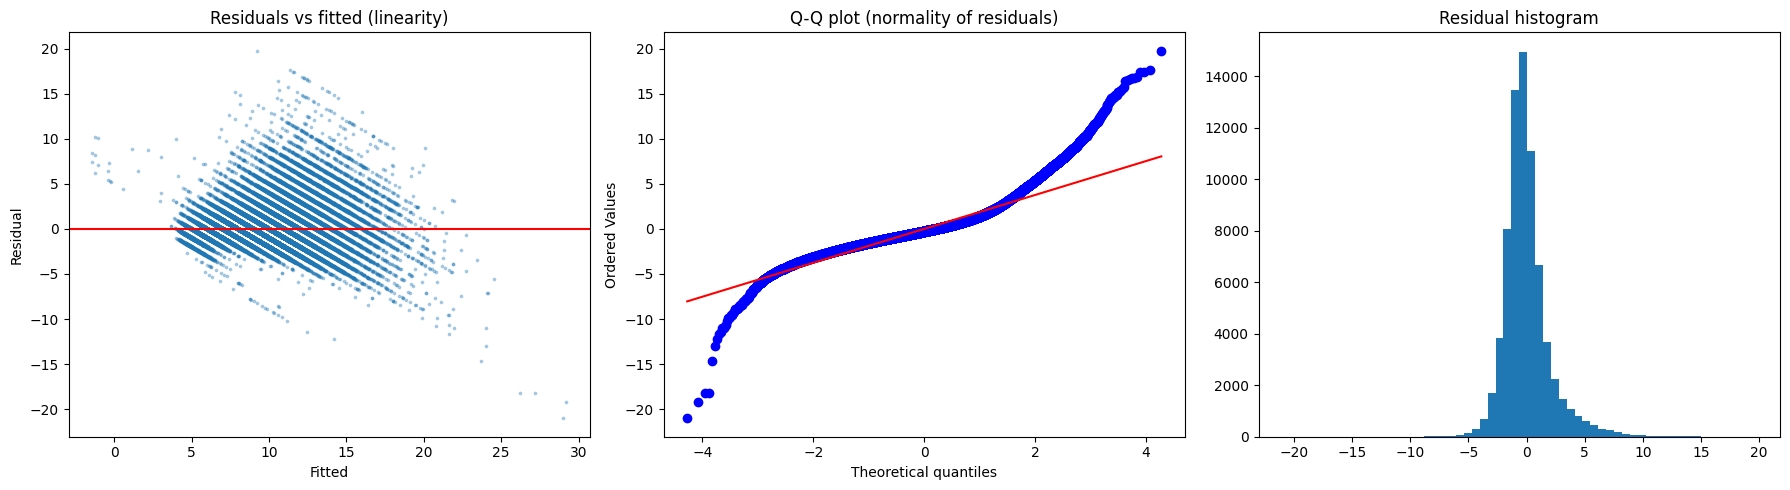

          feature   VIF
0           const   1.0
1          Length  51.2
2        Diameter  54.3
3          Height   7.6
4    Whole weight  69.5
5  Whole weight.1  21.5
6  Whole weight.2  20.1
7    Shell weight  18.2
8           Sex_I   2.4
9           Sex_M   1.4
Durbin-Watson: 1.995
Breusch-Pagan p-value: 0.0
Skew: 1.43 Kurtosis: 6.61


In [7]:
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

Xc = sm.add_constant(X_tr)
resid = ols.resid
fitted = ols.fittedvalues

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(fitted, resid, s=3, alpha=0.3)
ax[0].axhline(0, color='red')
ax[0].set_title('Residuals vs fitted (linearity)')
ax[0].set_xlabel('Fitted'); ax[0].set_ylabel('Residual')
stats.probplot(resid, plot=ax[1])
ax[1].set_title('Q-Q plot (normality of residuals)')
ax[2].hist(resid, bins=60)
ax[2].set_title('Residual histogram')
plt.tight_layout(); plt.show()

vif = pd.DataFrame({'feature': Xc.columns,
                    'VIF': [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
print(vif.round(1))
print('Durbin-Watson:', round(durbin_watson(resid), 3))
print('Breusch-Pagan p-value:', het_breuschpagan(resid, Xc)[1])
print('Skew:', round(stats.skew(resid), 2), 'Kurtosis:', round(stats.kurtosis(resid), 2))